# Cómo se invierte el dinero: Plan 4 (LDI con trinquete) frente al Plan 3

Resumen del proyecto pensado para pasar a diapositivas. **No calcula nada nuevo**: lee `config/assumptions.yaml`, los
pronósticos de `data/forecasts/`, los datos de mercado de `data/raw/` y los resultados que ya escribieron
`uvr_loan.backtest` y `uvr_loan.synthetic` en `results/`. No guarda imágenes ni archivos.

| Sección | Contenido | Diapositivas sugeridas |
|---|---|---|
| 1 | El problema y sus parámetros | 1–2 |
| 2 | Mapa del proyecto: qué hace cada archivo y de dónde sale cada dato | 1 |
| 3 | Las tasas: inflación (Nelson-Siegel + Hull-White), CDT y FIC | 3–4 |
| 4 | Regla de inversión del Plan 4, con un ejemplo numérico | 2–3 |
| 5 | Backtest real oct-2016 → oct-2026: Plan 4 frente al Plan 3 | 4–5 |
| 6 | Caso en que los ETF pierden valor (`both_down`) | 4–5 |
| 7 | Conclusiones y límites | 1 |

In [1]:
import logging

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter

from uvr_loan.amortization import installment
from uvr_loan.config import BACKTEST_DIR, ROOT, SYNTHETIC_DIR, load_assumptions
from uvr_loan.data.cleaning import load_monthly_panel
from uvr_loan.data.sources import load_uvr
from uvr_loan.inflation_model.cpi import cpi_target
from uvr_loan.inflation_model.hull_white import simulate_hull_white
from uvr_loan.inflation_model.nelson_siegel import implied_inflation, load_betas, nelson_siegel_nodes, rolling_std

logging.getLogger("uvr_loan.data.cleaning").setLevel(logging.ERROR)

cfg = load_assumptions()
bt, loan = cfg["backtest"], cfg["loan"]
T0 = pd.Period(bt["t0"], "M")
GRACE_END = (T0 + loan["grace_months"]).to_timestamp(how="end").normalize()

# Misma paleta que notebooks/backtest_plans.ipynb (Okabe-Ito para planes, Paul Tol para instrumentos).
COLORS = {"ldi": "#009E73", "ratchet_ldi": "#942C18"}
PLANS = {"ldi": "LDI", "ratchet_ldi": "LDI con protección de ganancias"}
SHORT = {"ldi": "LDI", "ratchet_ldi": "LDI con protección de ganancias"}
INSTRUMENTS = {
    "fic_cop": ("FIC", "#88CCEE"),
    "cdt_cop": ("CDT", "#44AA99"),
    "icolcap_cop": ("ETF ICOLCAP", "#DDCC77"),
    "cspx_cop": ("ETF CSPX", "#AA4499"),
}
TEXT, TEXT_2, GRID, SURFACE, GRACE = "#1a1a1a", "#5c5b57", "#e2e1dc", "#fcfcfb", "#efeeea"
BLUE, GREEN, ORANGE = "#1f6fb2", "#2b8a3e", "#d9480f"
FIG = (10.5, 5.2)  # una sola figura por gráfica, con la proporción de una diapositiva

# Letra grande: estas figuras se pegan en diapositivas.
plt.rcParams.update({
    "figure.facecolor": SURFACE, "figure.dpi": 130, "axes.facecolor": SURFACE, "axes.edgecolor": "#b9b8b2",
    "axes.labelcolor": TEXT_2, "axes.labelsize": 12, "axes.titlecolor": TEXT, "axes.titlesize": 16,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.7, "xtick.color": TEXT_2,
    "ytick.color": TEXT_2, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "legend.frameon": False, "legend.labelcolor": TEXT, "font.size": 12, "lines.linewidth": 2.4,
})


def es_number(x, decimals=0):
    # 1.234,5: punto de miles y coma decimal
    return f"{x:,.{decimals}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def es_pct(x, decimals=1):
    return es_number(100 * x, decimals) + " %"


def md_table(df):
    rows = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    rows += ["| " + " | ".join(map(str, r)) + " |" for r in df.itertuples(index=False)]
    display(Markdown("\n".join(rows)))


def month_dates(months):
    return pd.Series([(T0 + int(m)).to_timestamp(how="end").normalize() for m in months])


def header(ax, title, subtitle=""):
    ax.set_title(title, loc="left", pad=36 if subtitle else 14)
    if subtitle:
        ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, 10), textcoords="offset points",
                    color=TEXT_2, va="bottom", fontsize=12)


def style_time(ax, dates, ylabel="Millones de COP", grace=True, pad_days=0):
    # pad_days deja un margen a la derecha para poner el nombre de cada serie junto a su último punto
    if grace:
        ax.axvspan(dates.iloc[0], GRACE_END, color=GRACE, lw=0, zorder=0)
        ax.axvline(GRACE_END, color=TEXT_2, lw=0.9, ls=(0, (3, 3)), zorder=4)
        ax.annotate("Período de gracia", (dates.iloc[0], 1), xycoords=("data", "axes fraction"), xytext=(6, -6),
                    textcoords="offset points", va="top", color=TEXT_2, fontsize=10)
    ax.set_ylabel(ylabel)
    years = [pd.Timestamp(y, 1, 1) for y in range(dates.iloc[0].year, dates.iloc[-1].year + 1)]
    ax.set_xticks([mdates.date2num(d) for d in years if dates.iloc[0] <= d <= dates.iloc[-1]])
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: es_number(y)))
    ax.set_xlim(dates.iloc[0], dates.iloc[-1] + pd.Timedelta(days=pad_days))


def new_axes(title, subtitle, dates, ylabel="Millones de COP", grace=True, pad_days=0, figsize=FIG):
    fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    style_time(ax, dates, ylabel, grace, pad_days)
    header(ax, title, subtitle)
    return fig, ax


def end_label(ax, x, y, color, text, dy=0):
    ax.plot(x, y, "o", color=color, ms=7, mec=SURFACE, mew=1.5, zorder=5)
    ax.annotate(text, (x, y), xytext=(10, dy), textcoords="offset points", va="center", color=color,
                fontweight="bold", fontsize=11, annotation_clip=False)


def total_max(dfs):
    return max(sum(df[c] for c in INSTRUMENTS).max() for df in dfs) / 1e6


def composition(df, dates, ymax, title, subtitle):
    # Los dos planes se dibujan en figuras separadas pero con la misma escala vertical (ymax), para poder compararlos
    fig, ax = new_axes(title, subtitle, dates)
    used = [c for c in INSTRUMENTS if df[c].abs().max() > 0]
    ax.stackplot(dates, [df[c] / 1e6 for c in used], colors=[INSTRUMENTS[c][1] for c in used],
                 labels=[INSTRUMENTS[c][0] for c in used], edgecolor=SURFACE, linewidth=0.6, zorder=2)
    ax.set_ylim(0, ymax)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.01, 1), title="Instrumento",
              title_fontproperties={"weight": "bold", "size": 11}, alignment="left")
    plt.show()

## 1. El problema

Con **COP 760.000.000** hay que pagar un crédito de **1.000.000 UVR** (la UVR es la unidad indexada a la inflación):
cada cuota está fija en UVR y en pesos crece con la inflación. Se prueba con datos reales de oct-2016 a oct-2026.

El objetivo es **cero déficit** en cada pago (S2) y la **mayor riqueza final** posible. Una estrategia debe decidir
cuánto poner en cada instrumento: FIC (a la vista), CDT (tasa fija, no se retira antes de vencer) y ETF (acciones).

In [2]:
cuota = installment(loan["principal_uvr"], loan["annual_rate"], loan["term_months"], loan["grace_months"],
                    loan["prepayments_uvr"])
prepay = ", ".join(f"{es_number(v)} UVR en el mes {m}" for m, v in loan["prepayments_uvr"].items())
md_table(pd.DataFrame({
    "Parámetro": ["Capital inicial", "Crédito", "Plazo", "Tasa", "Gracia", "Abonos pactados", "Cuota fija (meses 37–120)",
                  "Inicio del backtest (t₀)", "Revisión del portafolio", "Inflación con la que se decide"],
    "Valor": [f"{es_number(cfg['initial_capital_cop'])} COP", f"{es_number(loan['principal_uvr'])} UVR",
              f"{loan['term_months']} meses", f"UVR + {es_pct(loan['annual_rate'], 0)} E.A.",
              f"{loan['grace_months']} meses, intereses capitalizados", prepay, f"{es_number(cuota, 4)} UVR",
              f"{bt['t0']} (mes 0)", f"cada {bt['review_every_months']} meses",
              f"escenario base = mediana del pronóstico Hull-White (`source: {cfg['inflation_scenarios']['source']}`)"],
}))

| Parámetro | Valor |
|---|---|
| Capital inicial | 760.000.000 COP |
| Crédito | 1.000.000 UVR |
| Plazo | 120 meses |
| Tasa | UVR + 10 % E.A. |
| Gracia | 36 meses, intereses capitalizados |
| Abonos pactados | 50.000 UVR en el mes 48, 50.000 UVR en el mes 60 |
| Cuota fija (meses 37–120) | 20.379,5327 UVR |
| Inicio del backtest (t₀) | 2016-10 (mes 0) |
| Revisión del portafolio | cada 6 meses |
| Inflación con la que se decide | escenario base = mediana del pronóstico Hull-White (`source: forecast`) |

## 2. Mapa del proyecto: qué hace cada cosa y de dónde sale cada dato

| Archivo | Qué hace | De dónde viene |
|---|---|---|
| `config/assumptions.yaml` | **Todos** los parámetros y supuestos (S1–S19): crédito, t₀, revisiones, inflación, planes, ETF sintéticos | Definido por el equipo |
| `docs/plan_proyecto_credito_uvr.md` | Plan de trabajo y lista de supuestos S1–S19 | Escrito por el equipo |
| `docs/reglas_de_inversion.md` | Regla exacta de los planes 1–4, con notación, ejemplos y simplificaciones | Escrito por el equipo |
| `docs/modelo_inflacion.md` | Cómo se pronostica la inflación (Hull-White) y qué cambió frente al código original | Escrito por el equipo |
| `data/SOURCES.md` | Endpoint, unidades y problemas conocidos de cada serie | Escrito por el equipo |
| `src/uvr_loan/amortization.py` | Cuota fija y tabla de pagos en UVR | Cálculo (fórmula de anualidad con gracia y abonos) |
| `src/uvr_loan/data/sources.py` | Descarga con caché en `data/raw/` | BanRep SUAMECA (UVR 850, CDT 65/67/68, TRM 1), Yahoo Finance (`ICOLCAP.CL`, `CSPX.L`), Superfinanciera `qhpu-8ixx` (FIC) |
| `src/uvr_loan/data/cleaning.py` | Panel mensual (`monthly_panel`): último dato de cada mes, tasas en decimales | `data/raw/` |
| `src/uvr_loan/inflation_model/` | Hull-White: betas Nelson-Siegel → inflación implícita → simulación → corrección → `hw_inflation_forecasts.csv` | Betas del Banco de la República (descargados a mano) |
| `src/uvr_loan/inflation.py` | Entrega los escenarios bajo / base / alto en cada revisión y proyecta la UVR | `data/forecasts/hw_inflation_forecasts.csv` (o UVR reciente si `source: trailing`) |
| `src/uvr_loan/portfolio.py` | Plan 1 (regla), LP de la escalera de CDT (plan 2), piso y pesos de los ETF (plan 3) | Programación lineal con `scipy` |
| `src/uvr_loan/backtest.py` | Simula mes a mes los 4 planes (`PLANS`), incluido el trinquete (`ratchet_ldi_strategy`) y las métricas | `monthly_panel` + los módulos anteriores |
| `src/uvr_loan/synthetic.py` | Repite los planes 2, 3 y 4 con precios de ETF inventados (8 escenarios × 2.000 caminos) | Browniano + deriva, caída, seno (`synthetic_etfs` del YAML) |
| `src/uvr_loan/forecast_runs.py` | Corre los planes con inflación `trailing` o `forecast` | Los mismos |
| `results/backtest/`, `results/synthetic/`, `results/forecast_runs*/` | CSV de salida de cada script | Generados por los módulos anteriores |
| `notebooks/backtest_plans.ipynb` | Gráficas de riqueza, liquidez, UVR proyectada y composición de los 4 planes | `results/backtest/` |
| `notebooks/synthetic_etf_scenarios.ipynb` | Planes 2–4 en los 8 escenarios sintéticos | `results/synthetic/` |
| `notebooks/inflation_estimate.ipynb` | Metodología de la inflación (sección 3) | `uvr_loan.inflation_model` |
| `tests/` | Pruebas de cada módulo (pytest) | – |

## 3. Las tasas

Los planes usan tres tipos de tasa y cada una tiene un papel distinto. Lo que **se decide** puede usar estimaciones
(con datos hasta la fecha de revisión); lo que **se reporta** sale solo de rendimientos observados.

| Tasa | Fuente | Para qué sirve |
|---|---|---|
| Inflación esperada (bajo / base / alto) | Pronóstico Hull-White a 6 meses (`hw_inflation_forecasts.csv`) | Proyectar la UVR y pasar tasas nominales a reales **al decidir** |
| CDT a 3, 6 y 12 meses | BanRep: DTF, CDT 180 y 360 días (series 65, 67, 68) | Rendimiento de los CDT **tal como se compraron**, hasta vencer |
| FIC | Índice de FIC de mercado monetario (Superfinanciera) | Rendimiento realizado mes a mes de la caja |
| ETF | Precios ajustados de ICOLCAP (en COP) y CSPX (USD × TRM) | Rendimiento realizado de la parte de crecimiento |

### 3.1 Cómo se estima la inflación

La idea: el mercado ya "descuenta" una inflación, y se puede leerla en la diferencia entre un TES en pesos y uno en UVR.

1. **Nelson-Siegel.** Con los betas diarios del Banco de la República se arman las curvas cero cupón de los TES en
   pesos y en UVR para plazos de 1 a 36 años.
2. **Inflación implícita (breakeven)** de cada plazo: $(1+\text{COP})/(1+\text{UVR})-1$.
3. **Hull-White** de un factor, con reversión a la media: $dI_t = (\theta(t) - a I_t)\,dt + \sigma\,dW_t$. Se simulan
   10.000 trayectorias de la curva implícita y se mira la inflación de los próximos 6 meses. La simulación queda centrada
   en la inflación implícita de hoy; aporta la **dispersión**. Parámetros: $\kappa$ = 0,11 / 0,13, $\sigma$ = percentil
   99,5 de la volatilidad móvil de 365 días.
4. **Corrección con la historia** (solo con meses ya realizados, sin mirar el futuro): sesgo, estacionalidad y la
   dispersión que le falta a la simulación. La inflación realizada se reconstruye de la UVR.
5. **Escenarios:** bajo = percentil 5, **base = mediana**, alto = percentil 99,5. Cada uno se usa como una inflación anual
   constante para todo el plazo que falta (no es un pronóstico a 10 años).

El cuaderno `inflation_estimate.ipynb` también incluye una versión didáctica más simple (un AR(1) sobre la inflación
semestral, con $\beta=e^{-a\Delta t}$ y $\alpha=\theta(1-e^{-a\Delta t})$) que quedó comentada: **el modelo que usan los
planes es el de este paquete**, no ese.

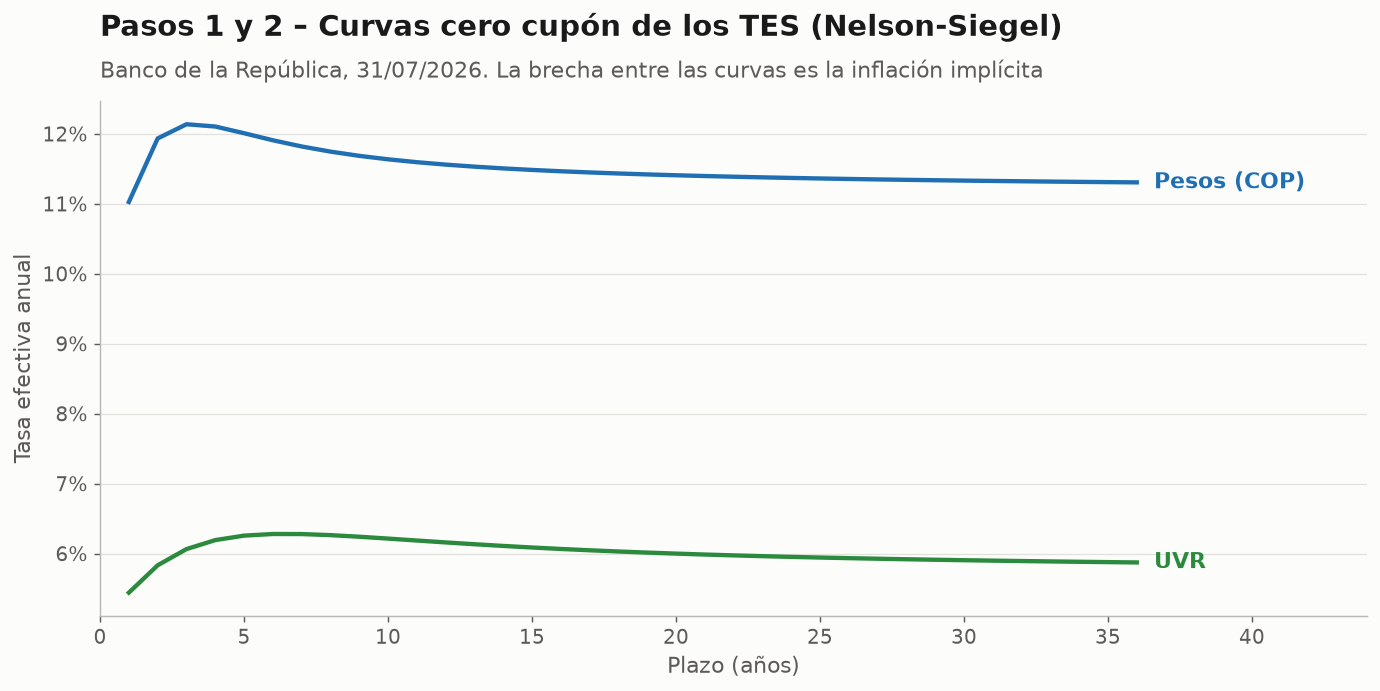

In [3]:
model = cfg["inflation_model"]
# El archivo descargado a mano se llama base_historica_betas.csv; la config espera betas_historicos.csv.
if not (ROOT / model["betas_file"]).exists():
    model["betas_file"] = "data/raw/base_historica_betas.csv"
betas = load_betas(cfg)
tenors = np.arange(1, model["tenors"] + 1)
known = betas  # última fecha disponible, la misma de inflation_estimate.ipynb
origin = known["date"].iloc[-1]
cop = nelson_siegel_nodes(known, tenors, "cop").iloc[-1]
uvr_curve = nelson_siegel_nodes(known, tenors, "uvr").iloc[-1]
implied = implied_inflation(known, tenors)
breakeven = implied.iloc[-1]

fig, ax = plt.subplots(figsize=FIG, layout="constrained")
ax.plot(tenors, cop, color=BLUE)
ax.plot(tenors, uvr_curve, color=GREEN)
ax.text(tenors[-1] + 0.6, cop.iloc[-1], "Pesos (COP)", color=BLUE, va="center", fontweight="bold")
ax.text(tenors[-1] + 0.6, uvr_curve.iloc[-1], "UVR", color=GREEN, va="center", fontweight="bold")
ax.set_xlim(0, tenors[-1] + 8)
ax.set_xlabel("Plazo (años)")
ax.set_ylabel("Tasa efectiva anual")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
header(ax, "Pasos 1 y 2 – Curvas cero cupón de los TES (Nelson-Siegel)",
       f"Banco de la República, {origin:%d/%m/%Y}. La brecha entre las curvas es la inflación implícita")
plt.show()

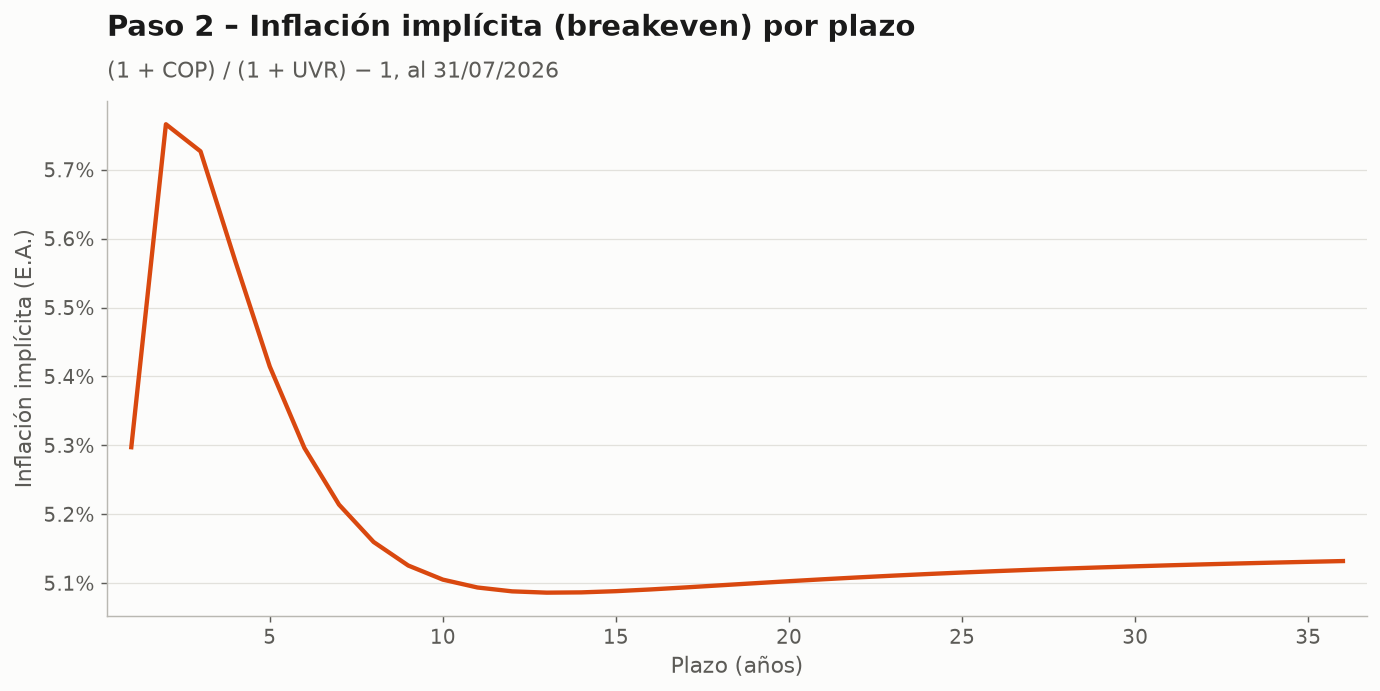

In [4]:
fig, ax = plt.subplots(figsize=FIG, layout="constrained")
ax.plot(tenors, breakeven, color=ORANGE)
ax.set_xlabel("Plazo (años)")
ax.set_ylabel("Inflación implícita (E.A.)")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.margins(x=0.02)
header(ax, "Paso 2 – Inflación implícita (breakeven) por plazo", f"(1 + COP) / (1 + UVR) − 1, al {origin:%d/%m/%Y}")
plt.show()

El breakeven de largo plazo (arriba, alrededor de 5 %) **no es** el escenario que usan los planes: es la inflación que
descuenta el mercado a cada plazo. Es la curva que se simula (paso 3) y los escenarios salen después del pronóstico a 6
meses, corregido con la historia (pasos 4 y 5).

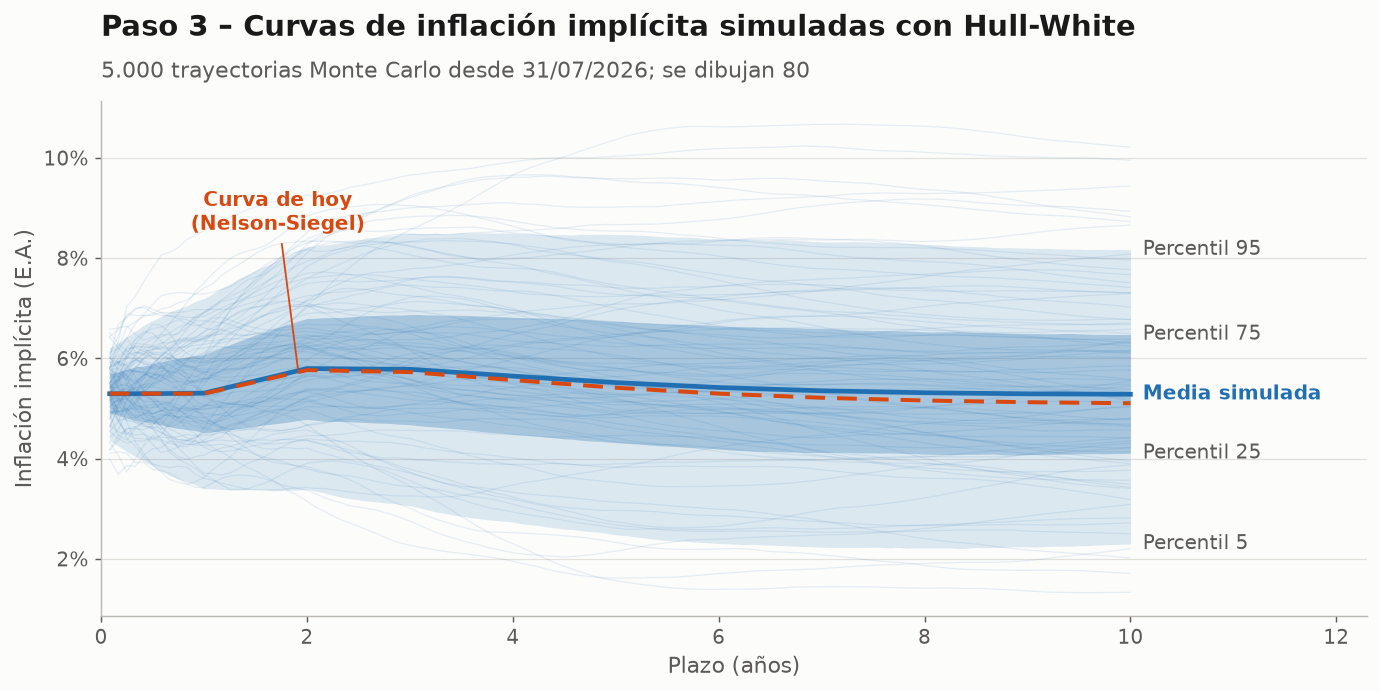

In [5]:
N_PATHS, YEARS, STEPS_PER_YEAR = 5000, 10, 12
sigma = rolling_std(implied, model["vol_window_days"]).quantile(model["vol_percentile"])
spot = implied.iloc[-1]
sim = simulate_hull_white(model["kappa_switch_years"], tuple(model["kappas"]), tenors, sigma, spot,
                          STEPS_PER_YEAR, YEARS, N_PATHS, model["seed"])
curves = sim["spot_rates"].to_numpy()  # una fila por trayectoria, una columna por plazo (años)
t = sim["time_axis"]
today = np.interp(t, tenors, spot.to_numpy())
q05, q25, q75, q95 = np.percentile(curves, [5, 25, 75, 95], axis=0)
mean = curves.mean(axis=0)
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=FIG, layout="constrained")
ax.plot(t, curves[rng.choice(N_PATHS, 80, replace=False)].T, color=BLUE, alpha=0.10, lw=0.7)
ax.fill_between(t, q05, q95, color=BLUE, alpha=0.14, lw=0)
ax.fill_between(t, q25, q75, color=BLUE, alpha=0.28, lw=0)
ax.plot(t, mean, color=BLUE, lw=2.6)
ax.plot(t, today, color=ORANGE, lw=2.2, ls=(0, (5, 3)))
for y, text, color, weight in [(q95[-1], "Percentil 95", TEXT_2, "normal"), (q75[-1], "Percentil 75", TEXT_2, "normal"),
                               (mean[-1], "Media simulada", BLUE, "bold"), (q25[-1], "Percentil 25", TEXT_2, "normal"),
                               (q05[-1], "Percentil 5", TEXT_2, "normal")]:
    ax.text(t[-1] + 0.12, y, text, color=color, va="center", fontweight=weight, fontsize=11)
ax.annotate("Curva de hoy\n(Nelson-Siegel)", xy=(t[22], today[22]), xytext=(t[22] - 0.2, today.max() + 0.028),
            color=ORANGE, fontweight="bold", fontsize=11, ha="center",
            arrowprops={"arrowstyle": "-", "color": ORANGE, "linewidth": 1})
ax.set_xlim(0, t[-1] + 2.3)
ax.set_xlabel("Plazo (años)")
ax.set_ylabel("Inflación implícita (E.A.)")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
header(ax, "Paso 3 – Curvas de inflación implícita simuladas con Hull-White",
       f"{N_PATHS:,} trayectorias Monte Carlo desde {origin:%d/%m/%Y}; se dibujan 80".replace(",", "."))
plt.show()

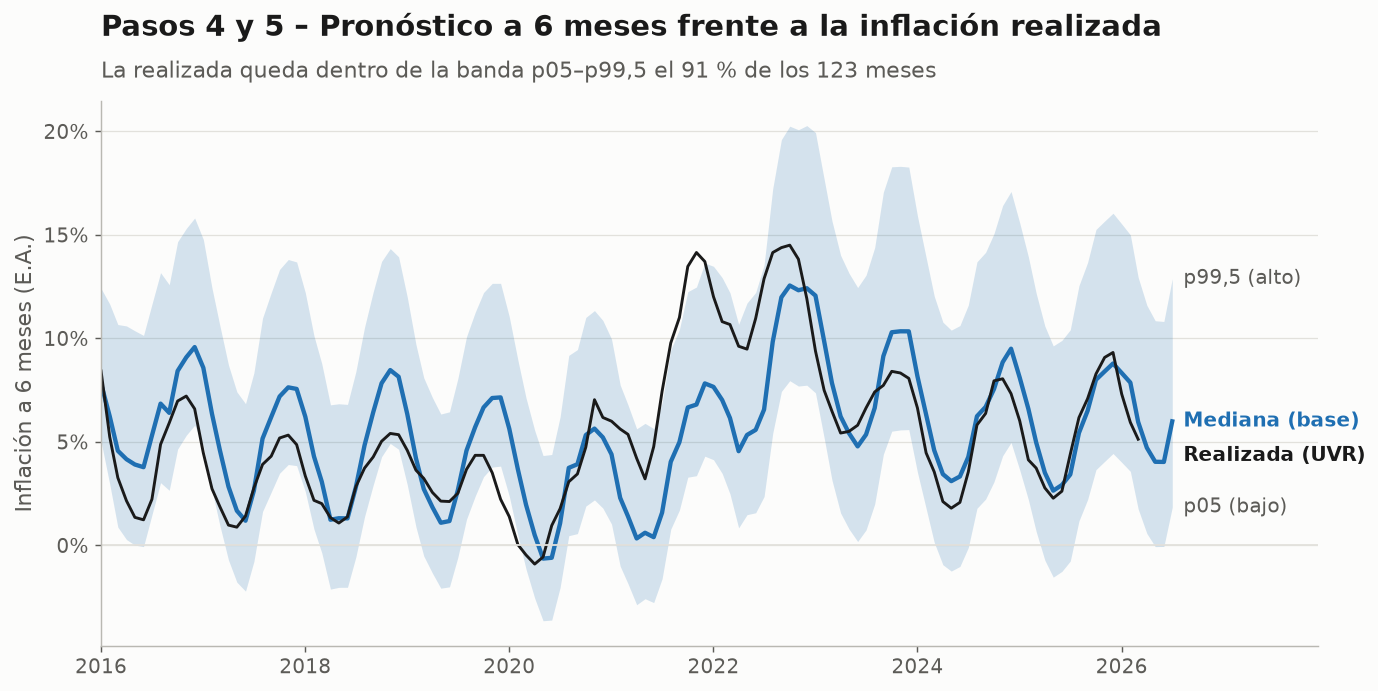

In [6]:
forecasts = pd.read_csv(ROOT / cfg["inflation_scenarios"]["forecast_file"], sep=";", index_col="month")
forecasts.index = pd.PeriodIndex(forecasts.index, freq="M")
uvr_daily = load_uvr(cfg)
realised = {}
for month in forecasts.index:
    try:
        realised[month] = cpi_target(uvr_daily, month.to_timestamp(how="end").normalize(), model["horizon_months"])
    except ValueError:  # el objetivo aún no se realiza
        pass
realised = pd.Series(realised)
f = forecasts.loc[realised.index]
inside = ((realised >= f["p05_ea"]) & (realised <= f["p995_ea"])).mean()
x = forecasts.index.to_timestamp()

fig, ax = plt.subplots(figsize=FIG, layout="constrained")
ax.fill_between(x, forecasts["p05_ea"], forecasts["p995_ea"], color=BLUE, alpha=0.18, lw=0)
ax.plot(x, forecasts["median_ea"], color=BLUE, lw=2.4)
ax.plot(realised.index.to_timestamp(), realised, color=TEXT, lw=1.6)
ax.axhline(0, color=GRID, lw=1)
x_last = x[-1] + pd.Timedelta(days=40)
for y, text, color in [(forecasts["p995_ea"].iloc[-1], "p99,5 (alto)", TEXT_2),
                       (forecasts["median_ea"].iloc[-1], "Mediana (base)", BLUE),
                       (forecasts["p05_ea"].iloc[-1], "p05 (bajo)", TEXT_2)]:
    ax.text(x_last, y, text, color=color, va="center", fontsize=11, fontweight="bold" if color == BLUE else None)
ax.text(x_last, realised.iloc[-1] - 0.008, "Realizada (UVR)", color=TEXT, va="center", fontweight="bold", fontsize=11)
ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=520))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
ax.set_ylabel("Inflación a 6 meses (E.A.)")
header(ax, "Pasos 4 y 5 – Pronóstico a 6 meses frente a la inflación realizada",
       f"La realizada queda dentro de la banda p05–p99,5 el {es_pct(inside, 0)} de los {len(realised)} meses")
plt.show()

### 3.2 Las tasas de los CDT y del FIC, y la inflación que deben vencer

Los CDT son de **tasa fija** al comprarlos: rinden lo que el BanRep publicaba ese día. Por eso el riesgo del plan es que
la inflación supere lo esperado (la cuota en pesos sube más que el dinero).

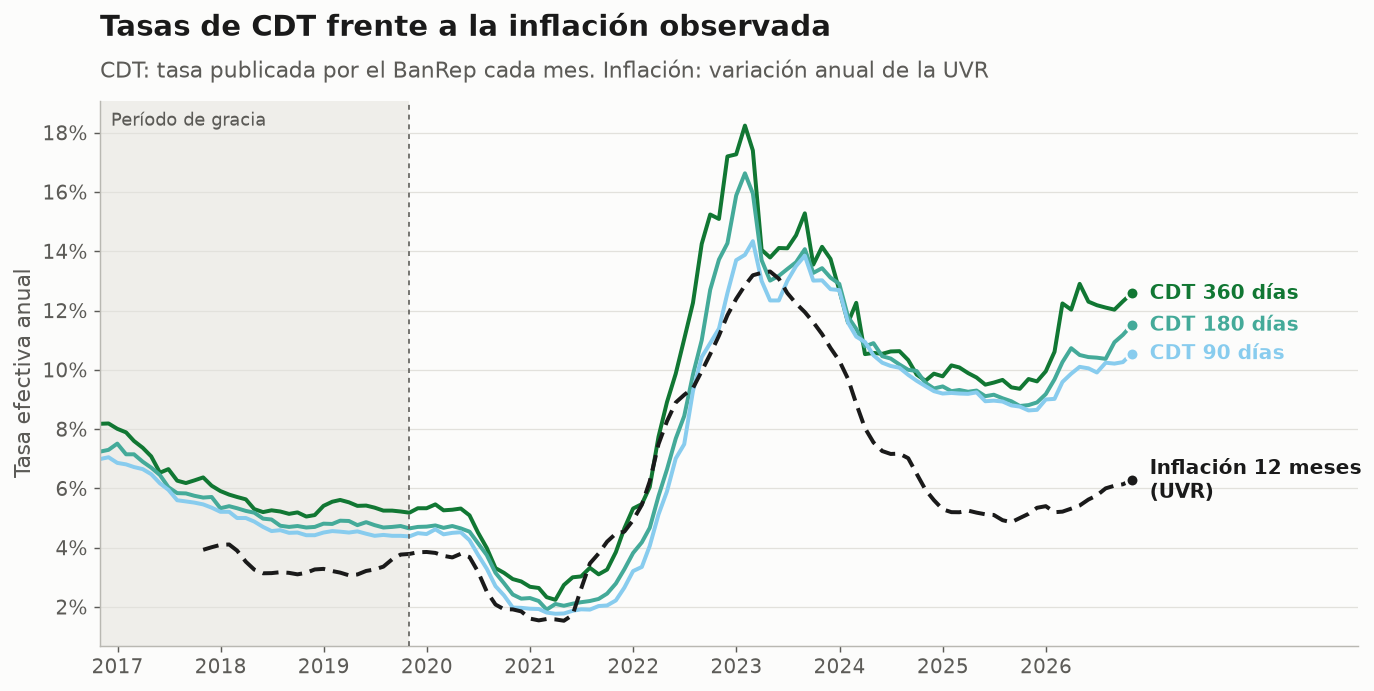

| Dato en oct-2016 (primera revisión) | Valor |
|---|---|
| CDT 90 días | 6,99 % |
| CDT 180 días | 7,24 % |
| CDT 360 días | 8,18 % |
| Inflación bajo (p05) | 4,65 % |
| Inflación base (mediana) | 8,43 % |
| Inflación alta (p99,5) | 14,67 % |
| FIC: rendimiento anual promedio de todo el horizonte | 6,62 % |

In [7]:
panel = load_monthly_panel(cfg).loc[T0:]
inflation_12m = panel["uvr_cop"] / panel["uvr_cop"].shift(12) - 1
dates = pd.Series(panel.index.to_timestamp(how="end").normalize())

fig, ax = new_axes("Tasas de CDT frente a la inflación observada",
                   "CDT: tasa publicada por el BanRep cada mes. Inflación: variación anual de la UVR",
                   dates, ylabel="Tasa efectiva anual", pad_days=800)
for series, label, color, style in [(panel["cdt_360d_ea"], "CDT 360 días", "#117733", "-"),
                                    (panel["cdt_180d_ea"], "CDT 180 días", "#44AA99", "-"),
                                    (panel["cdt_90d_ea"], "CDT 90 días", "#88CCEE", "-"),
                                    (inflation_12m, "Inflación 12 meses\n(UVR)", TEXT, (0, (4, 2)))]:
    ax.plot(dates, series.values, color=color, ls=style, lw=2.2)
    end_label(ax, dates.iloc[-1], series.dropna().iloc[-1], color, label)
ax.yaxis.set_major_locator(MultipleLocator(0.02))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
plt.show()

row, fc = panel.loc[T0], forecasts.loc[T0]
fic_avg = (panel["fic_index"].iloc[-1] / panel["fic_index"].iloc[0]) ** (12 / (len(panel) - 1)) - 1
md_table(pd.DataFrame({
    "Dato en oct-2016 (primera revisión)": ["CDT 90 días", "CDT 180 días", "CDT 360 días", "Inflación bajo (p05)",
                                           "Inflación base (mediana)", "Inflación alta (p99,5)",
                                           "FIC: rendimiento anual promedio de todo el horizonte"],
    "Valor": [es_pct(row["cdt_90d_ea"], 2), es_pct(row["cdt_180d_ea"], 2), es_pct(row["cdt_360d_ea"], 2),
              es_pct(fc["p05_ea"], 2), es_pct(fc["median_ea"], 2), es_pct(fc["p995_ea"], 2), es_pct(fic_avg, 2)],
}))

## 4. La regla de inversión del Plan 4

**Plan 3 (LDI, *liability-driven investment*).** Primero se cubren los pagos, después se invierte lo que sobra.

- **Piso** $B^{\min}_\tau$: el menor presupuesto con el que una escalera de CDT (3, 6 y 12 meses) + FIC cubre **todos** los
  pagos que faltan, calculado con un programa lineal en UVR con la inflación base.
- La escalera recibe $(1+b)\cdot$ piso, con $b$ = 5 %. **Todo lo que sobra va a ICOLCAP y CSPX**, repartido por volatilidad
  inversa (más al menos volátil). Es CPPI con multiplicador $\kappa=1$: aunque los ETF perdieran el 100 %, los pagos
  siguen cubiertos.
- Su debilidad: nunca vende después de ganar. Cuanto más se pagan cuotas, más sobra, y la parte en ETF llega a 97 %.

**Plan 4 = Plan 3 con trinquete (TIPP).** Solo cambia cuánto va a los ETF: protege una parte de la **mejor posición
alcanzada** y nunca la baja.

$$
S_\tau = A_\tau + V_\tau - L_\tau,\qquad S^{\max}_\tau=\max(S^{\max}_{\tau-k},\,S_\tau),\qquad
Z_\tau = L_\tau + \varphi\,\max(S^{\max}_\tau,0)
$$

$$
G_\tau = \min\Bigl(\max\bigl(\kappa\,(A_\tau + V_\tau - Z_\tau),\,0\bigr),\ \text{ETF que tendría el plan 3}\Bigr),\qquad \kappa = 1/\delta
$$

| Símbolo | Significado | Valor |
|---|---|---|
| $A_\tau$ | Dinero libre: FIC + ETF a precio de mercado | – |
| $V_\tau$ | Valor de los CDT vivos (a su tasa de compra) | – |
| $L_\tau$ | Pasivos: costo de una escalera nueva que cubra todos los pagos que faltan | – |
| $S_\tau$ | **Excedente** = activos − pasivos | – |
| $\varphi$ | Parte del mayor excedente que se protege (`protected_share`) | 0,80 |
| $\delta$ | Caída de los ETF entre dos revisiones que la regla absorbe (`max_fall`) | 0,25 → $\kappa$ = 4 |
| $Z_\tau$ | Nivel protegido del portafolio | – |
| $G_\tau$ | Dinero para los ETF; el resto de los activos va a CDT | – |

**Cómo se lee:** el *colchón* $A+V-Z$ es lo que los activos tienen por encima del nivel protegido. Cada peso de colchón
permite $\kappa=4$ pesos de ETF: una caída de 25 % de los ETF antes de la próxima revisión se come justo el colchón. Tras
una caída del excedente el colchón se achica y los ETF bajan 4 veces más rápido; con una caída de 20 % del máximo ya no
queda nada en ETF. El tope del plan 3 garantiza que el Plan 4 **nunca tiene más ETF que el Plan 3** y que la escalera
siempre recibe al menos $(1+b)$ × piso.

Lo demás es igual al plan 3 (ver `docs/reglas_de_inversion.md`): se compra solo en las revisiones (cada 6 meses), el pago
sale del FIC y, si no alcanza, se venden ETF a prorrata; los CDT no se redimen antes de vencer; sin costos ni impuestos.

### Ejemplo numérico: cuatro revisiones reales

Entradas ($A$, $V$, $L$, $S^{\max}$ y los ETF que tendría el plan 3) tomadas de la tabla de ejemplos de
`docs/reglas_de_inversion.md` (millones de COP). Todo lo demás se calcula aquí con la fórmula de arriba; las diferencias de ±0,2 con esa tabla vienen del redondeo de las entradas.

In [8]:
PHI, DELTA = cfg["ratchet_ldi"]["protected_share"], cfg["ratchet_ldi"]["max_fall"]
KAPPA = 1 / DELTA
# Revisión: (A, V, L, mayor excedente S_max incluida esta revisión, ETF que tendría el plan 3), de docs/reglas_de_inversion.md
examples = {
    "oct-2016": (760.0, 0.0, 447.8, 312.2, 289.8),
    "oct-2019": (951.4, 0.0, 515.1, 507.0, 410.5),
    "abr-2020": (360.3, 570.7, 403.9, 527.0, 331.1),
    "abr-2026": (852.6, 211.5, 49.2, 1014.9, 809.5),
}
rows = []
for name, (A, V, L, s_max, etf3) in examples.items():
    S = A + V - L
    Z = L + PHI * max(s_max, 0)
    cushion = A + V - Z
    G = min(max(KAPPA * cushion, 0), etf3)
    rows.append([name, es_number(S, 1), es_number(s_max, 1), es_number(Z, 1), es_number(cushion, 1),
                 es_number(KAPPA * cushion, 1), es_number(etf3, 1), es_number(G, 1),
                 "el trinquete" if KAPPA * cushion < etf3 else "el tope del plan 3"])
md_table(pd.DataFrame(rows, columns=["Revisión", "Excedente S", "Máx. S", "Nivel protegido Z", "Colchón A+V−Z",
                                      "κ × colchón", "ETF plan 3 (tope)", "ETF plan 4 (G)", "Manda"]))

| Revisión | Excedente S | Máx. S | Nivel protegido Z | Colchón A+V−Z | κ × colchón | ETF plan 3 (tope) | ETF plan 4 (G) | Manda |
|---|---|---|---|---|---|---|---|---|
| oct-2016 | 312,2 | 312,2 | 697,6 | 62,4 | 249,8 | 289,8 | 249,8 | el trinquete |
| oct-2019 | 436,3 | 507,0 | 920,7 | 30,7 | 122,8 | 410,5 | 122,8 | el trinquete |
| abr-2020 | 527,1 | 527,0 | 825,5 | 105,5 | 422,0 | 331,1 | 331,1 | el tope del plan 3 |
| abr-2026 | 1.014,9 | 1.014,9 | 861,1 | 203,0 | 811,9 | 809,5 | 809,5 | el tope del plan 3 |

En oct-2016 el excedente está en su máximo y el plan 4 pone $0{,}8\,S$ en ETF (un poco menos que el plan 3). En oct-2019 el
excedente está 14 % por debajo de su máximo y los ETF caen a 30 % de lo que tendría el plan 3. En abr-2020 y abr-2026 el
excedente es grande frente a los pasivos que quedan y manda el tope: el plan 4 iguala al plan 3.

## 5. Backtest real (oct-2016 → oct-2026): Plan 4 frente al Plan 3

Resultados de `python -m uvr_loan.backtest` con inflación del pronóstico Hull-White (escenario base). Una sola historia:
en esos 10 años las acciones subieron.

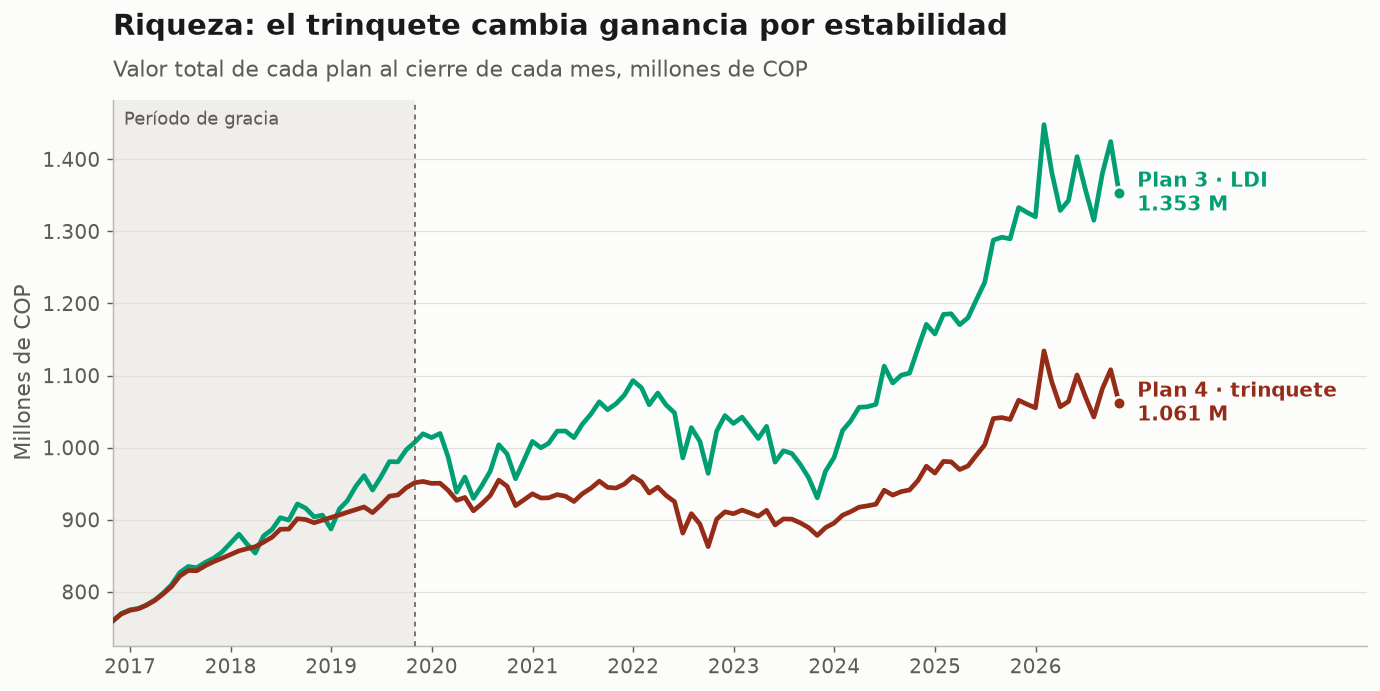

In [9]:
results = {}
for plan in PLANS:
    df = pd.read_csv(BACKTEST_DIR / f"{plan}.csv")
    df["date"] = pd.PeriodIndex(df["period"], freq="M").to_timestamp(how="end").normalize()
    results[plan] = df
dates = results["ldi"]["date"]
summary = pd.read_csv(BACKTEST_DIR / "summary.csv").set_index("metric")

fig, ax = new_axes("Riqueza: la protección de ganancias cambia rendimiento por estabilidad",
                   "Valor total de cada plan al cierre de cada mes, millones de COP", dates, pad_days=900)
for plan, df in results.items():
    wealth = df["wealth_cop"] / 1e6
    ax.plot(df["date"], wealth, color=COLORS[plan], lw=2.6, zorder=3)
    end_label(ax, df["date"].iloc[-1], wealth.iloc[-1], COLORS[plan], f"{SHORT[plan]}\n{es_number(wealth.iloc[-1])} M")
plt.show()

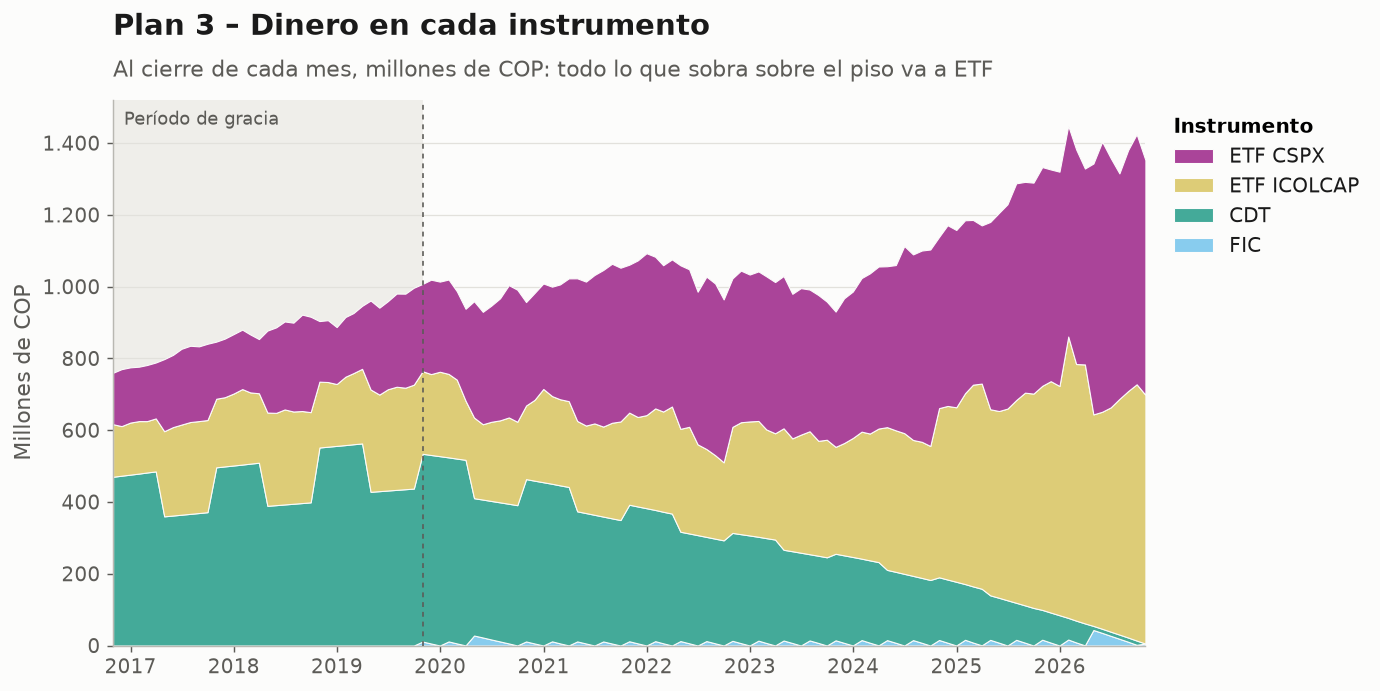

In [10]:
ymax = 1.05 * total_max(results.values())  # misma escala en las dos figuras de composición
composition(results["ldi"], dates, ymax, "LDI – Dinero en cada instrumento",
            "Al cierre de cada mes, millones de COP: todo lo que sobra sobre el piso va a ETF")

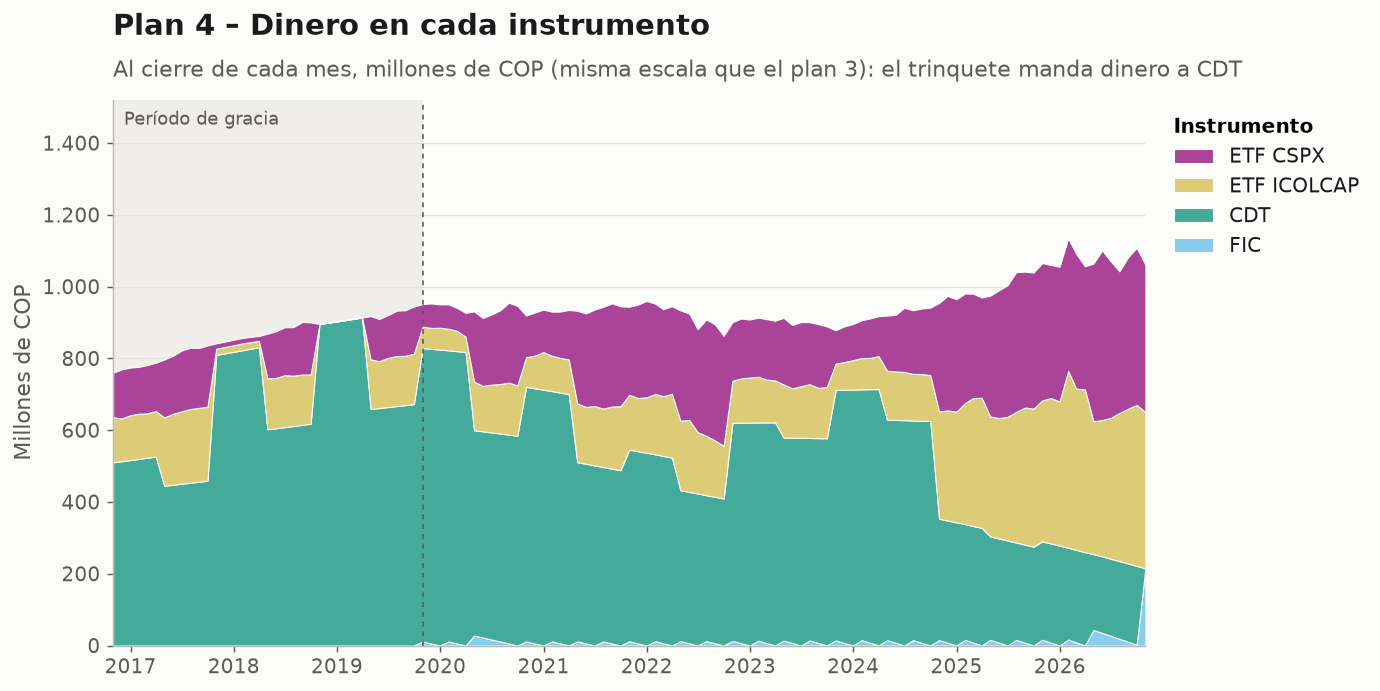

In [11]:
composition(results["ratchet_ldi"], dates, ymax, "LDI con protección de ganancias – Dinero en cada instrumento",
            "Al cierre de cada mes, millones de COP (misma escala que el LDI): la protección de ganancias manda dinero a CDT")

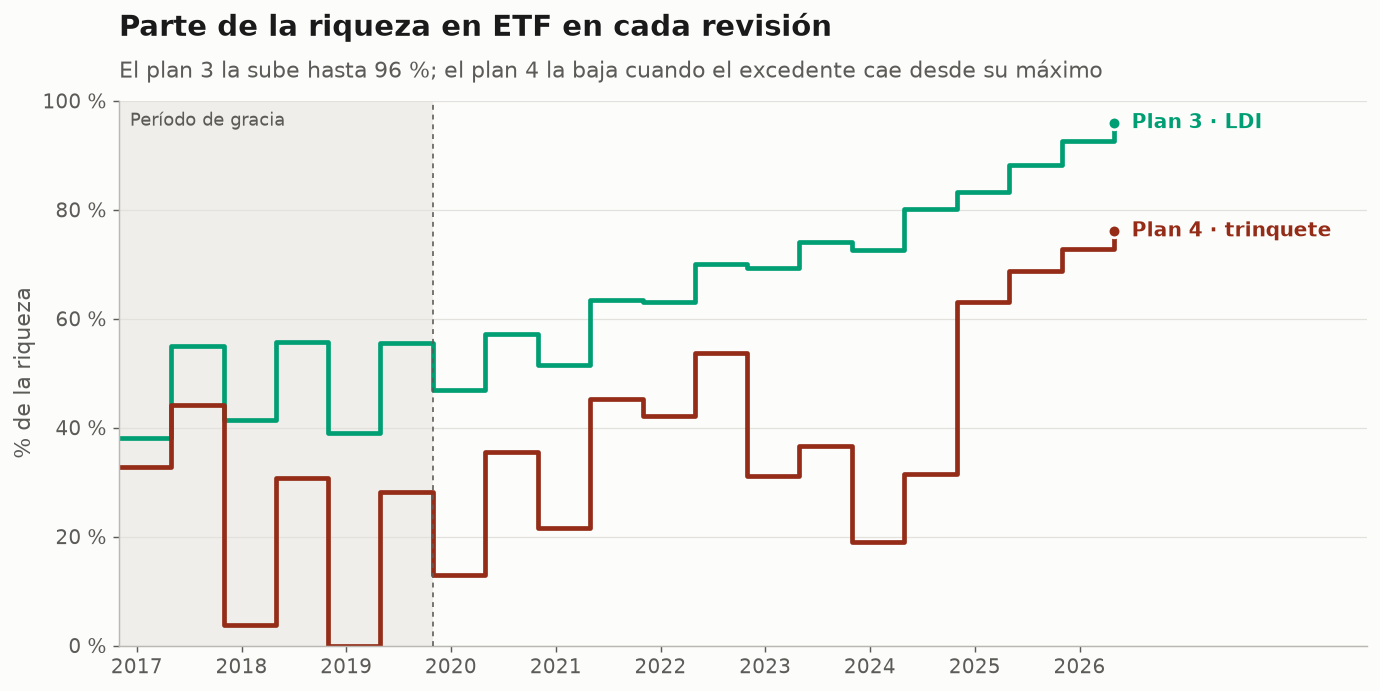

In [12]:
fig, ax = new_axes("Parte de la riqueza en ETF en cada revisión",
                   "El LDI la sube hasta 96 %; el LDI con protección de ganancias la baja cuando el excedente cae desde su máximo",
                   dates, ylabel="% de la riqueza", pad_days=700)
for plan in PLANS:
    r = results[plan][results[plan]["is_review"]]
    share = 100 * r["etf_cop"] / r["wealth_cop"]
    ax.step(r["date"], share, where="post", color=COLORS[plan], lw=2.6)
    end_label(ax, r["date"].iloc[-1], share.iloc[-1], COLORS[plan], SHORT[plan])
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.0f} %"))
plt.show()

In [13]:
s = summary[list(PLANS)]
md_table(pd.DataFrame({
    "Métrica": ["Riqueza final neta (M COP)", "Rentabilidad anual", "Volatilidad anual", "Máxima caída",
                "Liquidez mínima en un mes de pago (M COP)", "Meses con déficit", "ETF vendidos para pagar (COP)"],
    **{PLANS[p]: [es_number(s.loc["final_wealth_net_cop", p] / 1e6, 1), es_pct(s.loc["annual_return", p]),
                  es_pct(s.loc["annual_volatility", p]), es_pct(s.loc["max_drawdown", p]),
                  es_number(s.loc["min_liquid_at_payment_cop", p] / 1e6, 1), es_number(s.loc["shortfall_months", p]),
                  es_number(s.loc["total_etf_sold_cop", p])] for p in PLANS},
}))

| Métrica | Plan 3 – LDI | Plan 4 – LDI con trinquete |
|---|---|---|
| Riqueza final neta (M COP) | 1.352,7 | 1.061,4 |
| Rentabilidad anual | 11,9 % | 10,1 % |
| Volatilidad anual | 8,5 % | 5,7 % |
| Máxima caída | 7,1 % | 5,4 % |
| Liquidez mínima en un mes de pago (M COP) | 421,2 | 109,3 |
| Meses con déficit | 0 | 0 |
| ETF vendidos para pagar (COP) | 1.243.885 | 1.243.895 |

## 6. Cuando los ETF pierden valor: escenario sintético `both_down`

Los dos ETF tienen una deriva de **−15 % anual** con ruido (`synthetic_etfs.scenarios.both_down`). Se mantienen
históricos la UVR, las tasas de CDT, el FIC y los pagos; solo cambian los precios de los ETF desde t₀. Hay 2.000 caminos
aleatorios de una misma semilla; las primeras gráficas muestran el **camino 0** (un ejemplo) y la última, los 2.000.

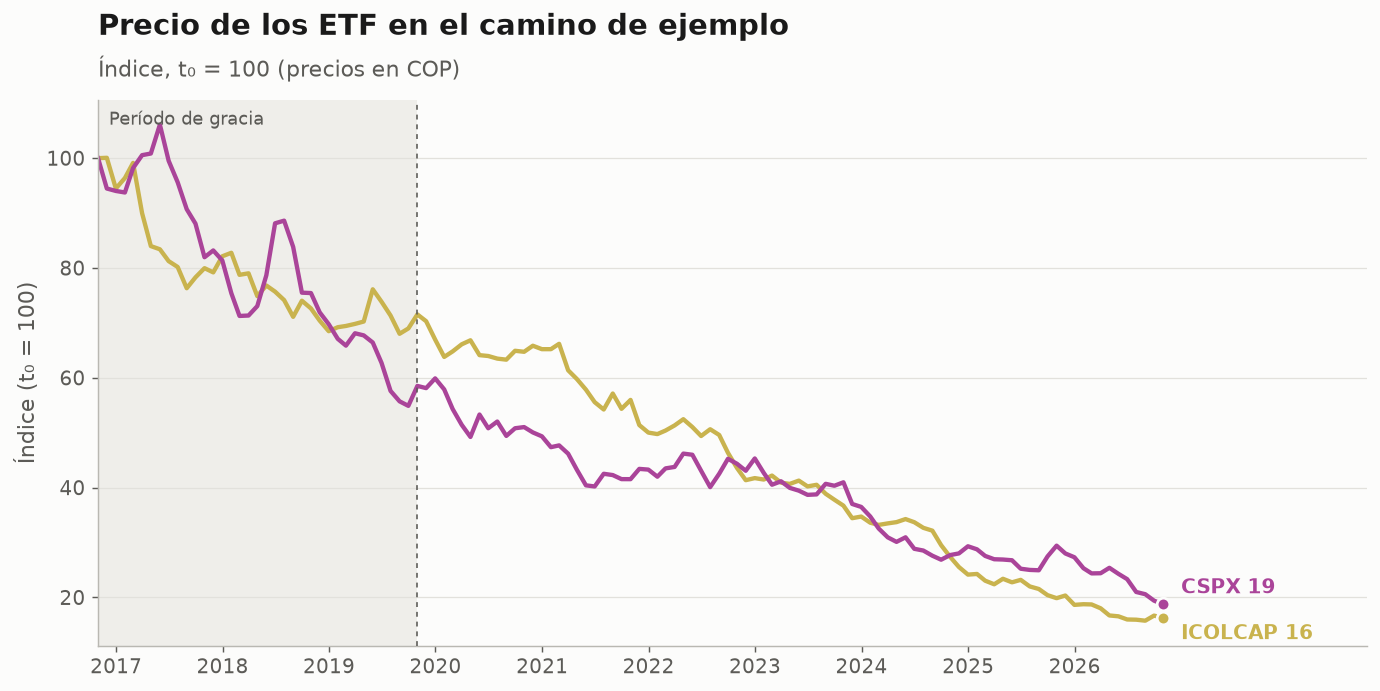

In [14]:
SC = "both_down"
runs = {}
for plan in PLANS:
    r = pd.read_csv(SYNTHETIC_DIR / SC / f"{plan}.csv")
    r["date"] = pd.PeriodIndex(r["period"], freq="M").to_timestamp(how="end").normalize()
    runs[plan] = r
sdates = runs["ldi"]["date"]
prices = pd.read_csv(SYNTHETIC_DIR / "prices.csv").query("scenario == @SC").set_index("month")
syn = pd.read_csv(SYNTHETIC_DIR / "summary.csv").query("scenario == @SC").set_index("plan")
fan = pd.read_csv(SYNTHETIC_DIR / "fan.csv").query("scenario == @SC")

fig, ax = new_axes("Precio de los ETF en el camino de ejemplo", "Índice, t₀ = 100 (precios en COP)", sdates,
                   ylabel="Índice (t₀ = 100)", pad_days=700)
for col, label, color, dy in [("icolcap_price_cop", "ICOLCAP", "#C9B34E", -9), ("cspx_price_cop", "CSPX", "#AA4499", 9)]:
    idx = 100 * prices[col] / prices[col].iloc[0]
    ax.plot(sdates, idx.values, color=color)
    end_label(ax, sdates.iloc[-1], idx.iloc[-1], color, f"{label} {idx.iloc[-1]:.0f}", dy=dy)
plt.show()

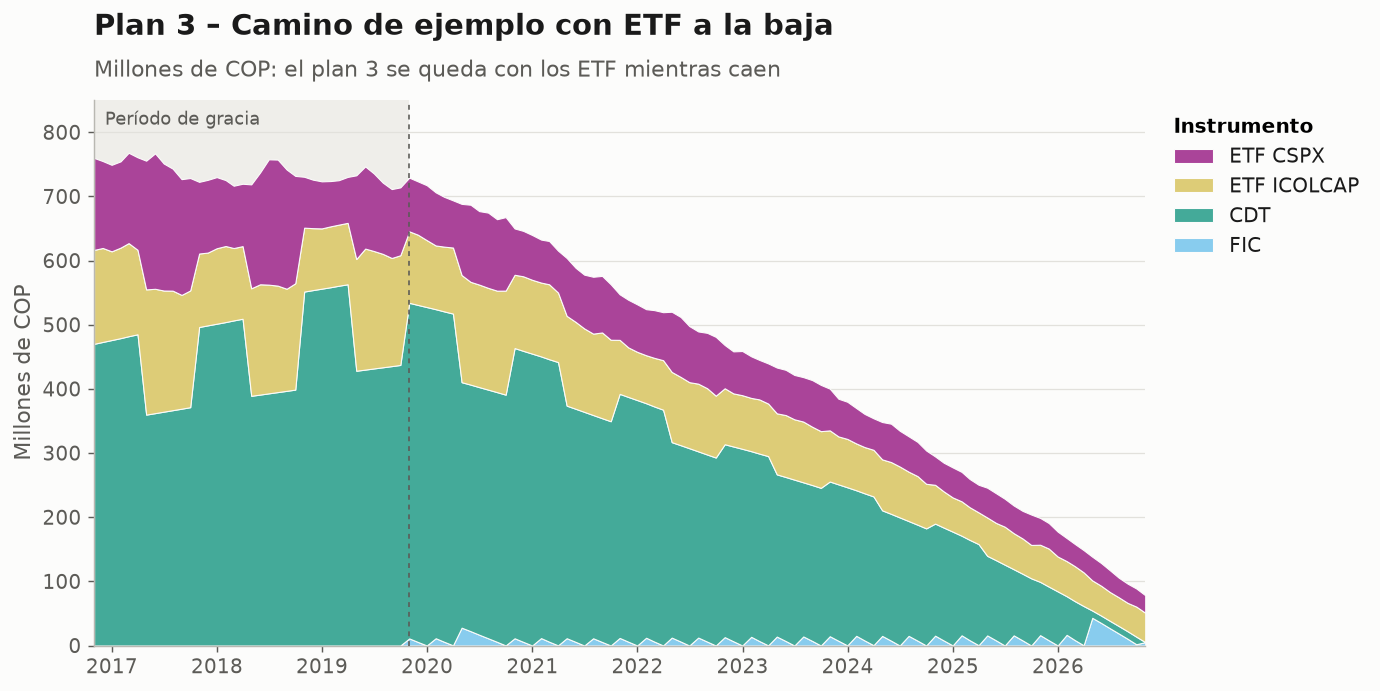

In [15]:
ymax = 1.05 * total_max(runs.values())
composition(runs["ldi"], sdates, ymax, "LDI – Camino de ejemplo con ETF a la baja",
            "Millones de COP: el LDI se queda con los ETF mientras caen")

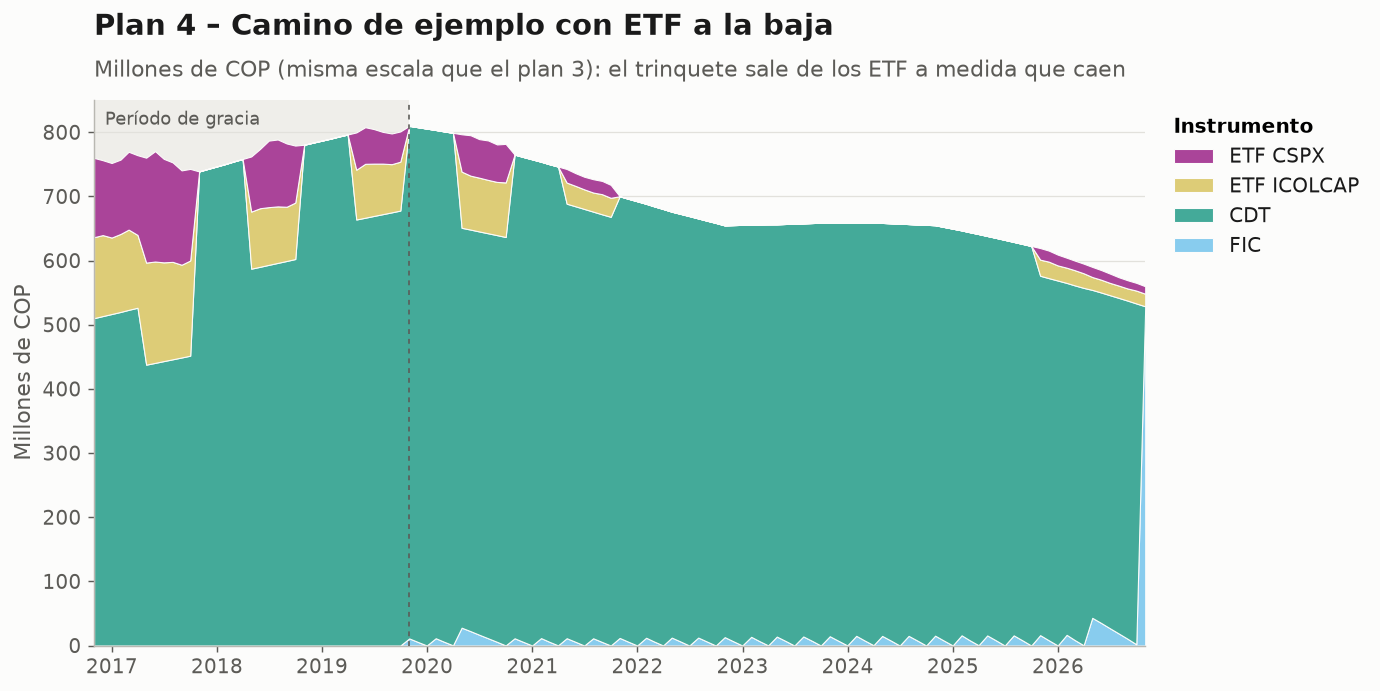

In [16]:
composition(runs["ratchet_ldi"], sdates, ymax, "LDI con protección de ganancias – Camino de ejemplo con ETF a la baja",
            "Millones de COP (misma escala que el LDI): la protección de ganancias retira los ETF a medida que caen")

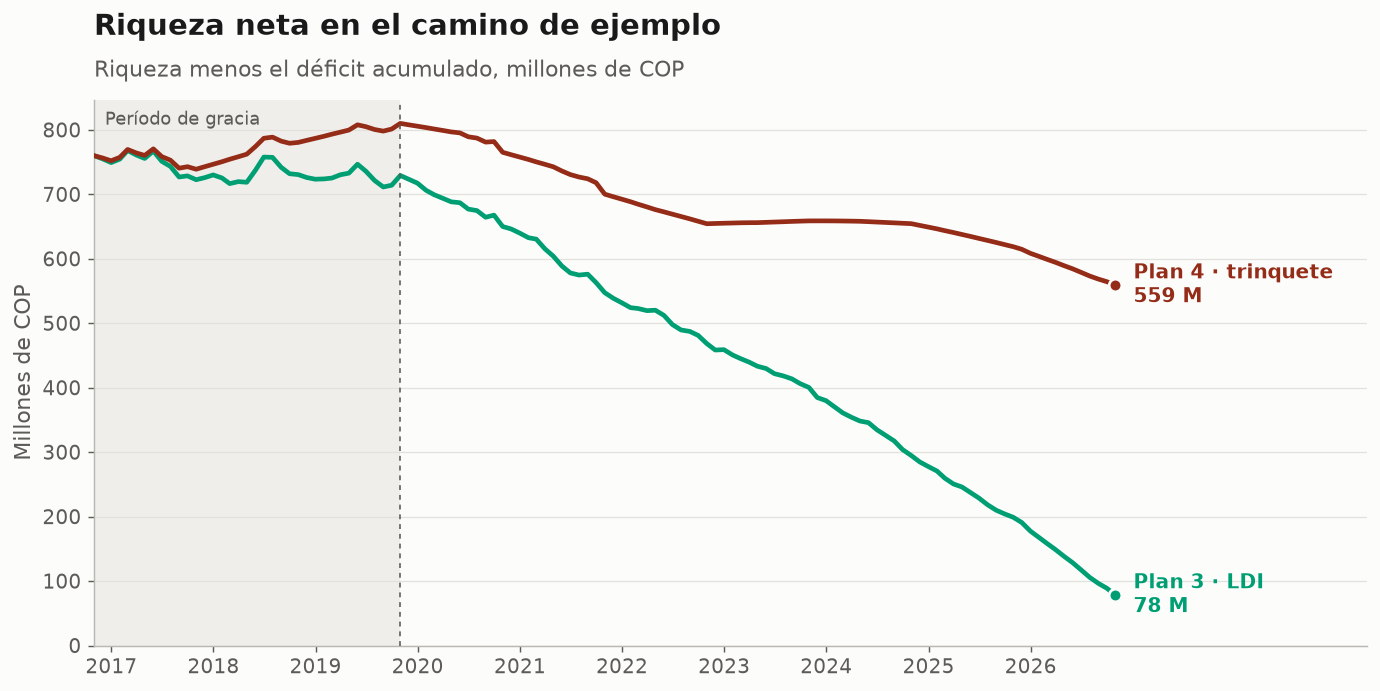

In [17]:
fig, ax = new_axes("Riqueza neta en el camino de ejemplo", "Riqueza menos el déficit acumulado, millones de COP", sdates,
                   pad_days=900)
for plan, r in runs.items():
    w = r["wealth_net_cop"] / 1e6
    ax.plot(r["date"], w, color=COLORS[plan], lw=2.6, zorder=3)
    end_label(ax, r["date"].iloc[-1], w.iloc[-1], COLORS[plan], f"{SHORT[plan]}\n{es_number(w.iloc[-1])} M")
ax.set_ylim(bottom=0)
plt.show()

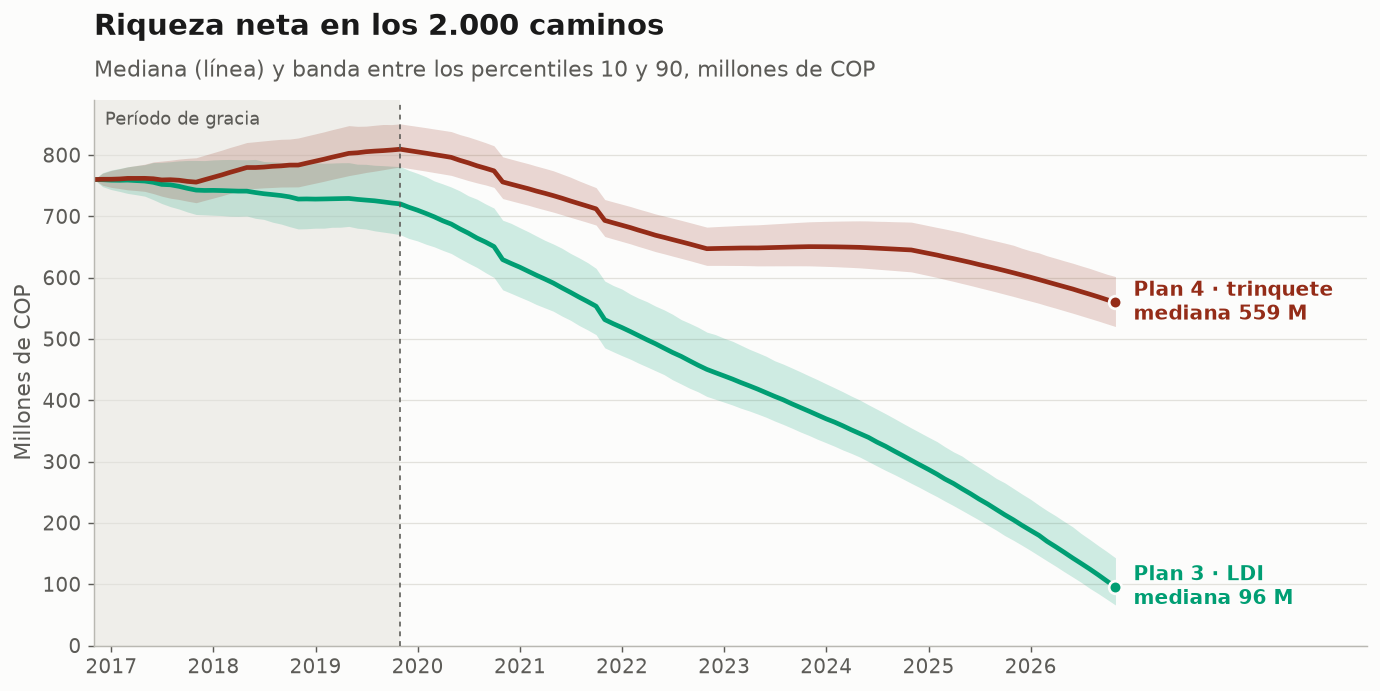

In [18]:
fdates = month_dates(sorted(fan["month"].unique()))
fig, ax = new_axes("Riqueza neta en los 2.000 caminos", "Mediana (línea) y banda entre los percentiles 10 y 90, millones de COP",
                   fdates, pad_days=900)
for plan in PLANS:
    g = fan[fan["plan"] == plan]
    ax.fill_between(fdates, g["p10"] / 1e6, g["p90"] / 1e6, color=COLORS[plan], alpha=0.18, lw=0)
    ax.plot(fdates, g["p50"] / 1e6, color=COLORS[plan], lw=2.6)
    end_label(ax, fdates.iloc[-1], g["p50"].iloc[-1] / 1e6, COLORS[plan],
              f"{SHORT[plan]}\nmediana {es_number(g['p50'].iloc[-1] / 1e6)} M")
ax.set_ylim(bottom=0)
plt.show()

In [19]:
rows = []
for p in PLANS:
    row, r = syn.loc[p], runs[p]
    rows.append([PLANS[p], es_number(row["wealth_p10"] / 1e6, 1), es_number(row["wealth_p50"] / 1e6, 1),
                 es_number(row["wealth_p90"] / 1e6, 1), es_pct(row["drawdown_mean"]), es_pct(row["shortfall_share"], 1),
                 es_number(r["shortfall_cop"].sum() / 1e6, 2), es_number(r["wealth_net_cop"].iloc[-1] / 1e6, 1)])
md_table(pd.DataFrame(rows, columns=["Plan", "Riqueza neta p10 (M)", "p50 (M)", "p90 (M)", "Caída máx. promedio",
                                      "Caminos con algún déficit", "Camino 0: déficit (M COP)", "Camino 0: riqueza neta (M)"]))
print(f"El plan 4 termina con más riqueza neta que el plan 3 en el {es_pct(syn.loc['ratchet_ldi', 'beats_plan3'], 1)} de los caminos.")

| Plan | Riqueza neta p10 (M) | p50 (M) | p90 (M) | Caída máx. promedio | Caminos con algún déficit | Camino 0: déficit (M COP) | Camino 0: riqueza neta (M) |
|---|---|---|---|---|---|---|---|
| Plan 3 – LDI | 66,0 | 95,5 | 143,0 | 18,2 % | 0,0 % | 0,00 | 78,4 |
| Plan 4 – LDI con trinquete | 520,3 | 559,5 | 601,8 | 4,0 % | 99,7 % | 0,79 | 559,2 |

El plan 4 termina con más riqueza neta que el plan 3 en el 100,0 % de los caminos.


**Qué se ve.** Cuando los ETF pierden valor, el plan 3 (todo lo que sobra en ETF) termina cerca de 100 M de COP: la escalera
cubre los pagos, pero la riqueza se destruye con las acciones. El plan 4 va sacando dinero de los ETF a medida que el
excedente cae, y termina cerca de 560 M.

**Un costo del plan 4 en este caso.** Casi todos los caminos tienen algún mes con déficit. Es pequeño (en el camino 0,
menos de 1 M de COP): cuando el trinquete ya sacó casi todos los ETF, el FIC queda corto por poco y no hay ETF que vender,
mientras que el plan 3 conserva algo de ETF para cubrirlo.

## 7. Conclusiones y límites

In [20]:
p3, p4 = summary["ldi"], summary["ratchet_ldi"]
display(Markdown(f"""
| | Plan 3 (LDI) | Plan 4 (trinquete) |
|---|---|---|
| **Backtest real**: riqueza final neta | {es_number(p3['final_wealth_net_cop'] / 1e6, 1)} M | {es_number(p4['final_wealth_net_cop'] / 1e6, 1)} M ({es_number((p4['final_wealth_net_cop'] - p3['final_wealth_net_cop']) / 1e6, 1)} M) |
| **Backtest real**: volatilidad / máxima caída | {es_pct(p3['annual_volatility'])} / {es_pct(p3['max_drawdown'])} | {es_pct(p4['annual_volatility'])} / {es_pct(p4['max_drawdown'])} |
| **ETF con pérdida (`both_down`)**: riqueza neta mediana | {es_number(syn.loc['ldi', 'wealth_p50'] / 1e6, 1)} M | {es_number(syn.loc['ratchet_ldi', 'wealth_p50'] / 1e6, 1)} M |
| **ETF con pérdida (`both_down`)**: caída máxima promedio | {es_pct(syn.loc['ldi', 'drawdown_mean'])} | {es_pct(syn.loc['ratchet_ldi', 'drawdown_mean'])} |

- Ambos planes cubren todas las cuotas del backtest real sin déficit.
- **El trinquete cambia ganancia por estabilidad:** pierde cuando las acciones suben y protege cuando caen.
"""))


| | Plan 3 (LDI) | Plan 4 (trinquete) |
|---|---|---|
| **Backtest real**: riqueza final neta | 1.352,7 M | 1.061,4 M (-291,3 M) |
| **Backtest real**: volatilidad / máxima caída | 8,5 % / 7,1 % | 5,7 % / 5,4 % |
| **ETF con pérdida (`both_down`)**: riqueza neta mediana | 95,5 M | 559,5 M |
| **ETF con pérdida (`both_down`)**: caída máxima promedio | 18,2 % | 4,0 % |

- Ambos planes cubren todas las cuotas del backtest real sin déficit.
- **El trinquete cambia ganancia por estabilidad:** pierde cuando las acciones suben y protege cuando caen.


**Límites que hay que decir en la presentación** (de `docs/`):

- **Una sola historia.** El backtest real es un único camino de 10 años en que las acciones subieron; los escenarios
  sintéticos son inventados (`both_down` es un caso extremo, ETF −78 % en la mediana).
- **El pronóstico de 6 meses se usa para 10 años.** Cada escenario de inflación es una tasa anual constante para todo el
  plazo que falta. La corrección con la historia usa pocos datos (unas 28 ventanas de 6 meses sin solapar), y la banda
  p99,5 es un escenario de estrés, no una expectativa.
- **Los CDT son de tasa fija:** si la inflación supera la esperada, las cuotas en pesos crecen más que el dinero.
- **El trinquete se revisa solo cada 6 meses:** una caída de más de $\delta$ = 25 % entre dos revisiones puede llevar el
  portafolio por debajo del nivel protegido, nunca por debajo del piso.
- **Supuestos operativos:** sin costos ni impuestos (S3, S6), venta inmediata al precio de cierre (S16), conversión a la TRM
  sin margen (S17), acceso sin trabas al ETF extranjero (S18), sin cobertura cambiaria (S19). Los TES quedan pendientes.